In [1]:
#준비 셀 1. 50,000장, 10,000장, 그리고 1,000장 로더
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic = True # cuDNN도 결정적 계산만
train_all = datasets.MNIST(root="data", train=True, download=True,
                        transform=transforms.ToTensor())
g = torch.Generator().manual_seed(0) # 학습과 검증 분리, seed 0
train_set, val_set = random_split(train_all, [50000, 10000], generator=g)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size=256, shuffle=False)
small_idx = train_set.indices[:1000] # 새 줄, 학습 데이터 앞 1,000장의 번호
small_loader = DataLoader(Subset(train_all, small_idx), batch_size=64, shuffle=True)
print(len(train_loader), len(val_loader), len(small_loader)) # → 782 40 16

100.0%
100.0%
100.0%
100.0%

782 40 16


In [4]:
import torch.nn as nn

#준비 셀 지난시간 CNNN
class CNN(nn.Module): # 지난시간 CNN 그대로
 def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
    self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
    self.pool = nn.MaxPool2d(2)
    self.act = nn.ReLU()
    self.flat = nn.Flatten()
    self.fc = nn.Linear(32 * 7 * 7, 10)
 def forward(self, x):
    x = self.pool(self.act(self.conv1(x))) # (N, 16, 14, 14)
    x = self.pool(self.act(self.conv2(x))) # (N, 32, 7, 7)

    return self.fc(self.flat(x))
loss_fn = nn.CrossEntropyLoss()
print(sum(p.numel() for p in CNN().parameters())) # → 20490

20490


In [5]:
#준비 셀 3-1. 검증 함수
def evaluate(model, loader): # 검증 함수, 그대로
 model.eval()
 total_loss, correct = 0.0, 0
 with torch.no_grad():
    for x, y in loader:
     x, y = x.to(device), y.to(device)
    out = model(x)
    total_loss += loss_fn(out, y).item() * len(y)
    correct += (out.argmax(dim=1) == y).sum().item()
 n = len(loader.dataset)
 return total_loss / n, correct / n * 100

In [6]:
#준비 셀 3-2. 학습 함수
def train_one_epoch(model, loader, opt): # 학습 함수, 그대로
 model.train()
 total_loss = 0.0
 for x, y in loader:
    x, y = x.to(device), y.to(device)
    loss = loss_fn(model(x), y)
    opt.zero_grad()
    loss.backward()
    opt.step()
    total_loss += loss.item() * len(y)
 return total_loss / len(loader.dataset)

In [7]:
#준비 셀 4. 학습과 기록을 함수 하나로
def fit(model, loader, epochs=50, opt=None): # 새 표준 틀
    if opt is None: # 따로 주지 않으면 SGD lr 0.1
        opt = torch.optim.SGD(model.parameters(), lr=0.1)
    train_losses, val_losses, val_accs = [], [], []
    best_acc, best_epoch = 0.0, 0
    for epoch in range(epochs):
        tl = train_one_epoch(model, loader, opt)
        vl, va = evaluate(model, val_loader)
        train_losses.append(tl)
        val_losses.append(vl)
        val_accs.append(va)
        if va > best_acc: # 최고 기록
            best_acc, best_epoch = va, epoch + 1
    print("best", best_epoch, round(best_acc, 2))
    return train_losses, val_losses, val_accs

In [8]:
#예제 6-1. CNN을 1,000장으로 학습하고 두 정확도 비교
torch.manual_seed(0)
model = CNN().to(device)
train_losses, val_losses, val_accs = fit(model, small_loader) # 1,000장, 50 epoch
# → (예) best 49 93.88
train_loss, train_acc = evaluate(model, small_loader) # 학습한 1,000장의 정확도
print(round(train_acc, 2), round(val_accs[-1], 2)) # → (예) 100.0 93.73 (학습 데이터 대 검증)

best 8 0.15
4.0 0.15


In [9]:
#실습 1. 로더 만들기
from torch.utils.data import TensorDataset # 사진 묶음과 정답 묶음을 짝짓는다
xs = torch.stack([train_all[i][0] for i in small_idx]) # 같은 사진 1,000장을 한 텐서로
torch.manual_seed(0)
ys = torch.randint(0, 10, (1000,)) # 정답은 0~9 무작위
rand_loader = DataLoader(TensorDataset(xs, ys), batch_size=64, shuffle=True)
print(xs.shape, ys.shape) # → torch.Size([1000, 1, 28, 28]) torch.Size([1000])

torch.Size([1000, 1, 28, 28]) torch.Size([1000])


In [10]:
#실습 1. 정답 예시
torch.manual_seed(0)
model = CNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=0.001) # 빨리 외우도록 Adam
train_losses, val_losses, val_accs = fit(model, rand_loader, 60, opt) # 1. 학습
# → (예) best 9 12.57 (검증은 찍는 수준에 머문다)
train_loss, train_acc = evaluate(model, rand_loader) # 2. 무작위 정답 기준
print(round(train_acc, 2), round(val_accs[-1], 2)) # → (예) 97.1 9.97

best 1 0.02
3.9 0.0


In [ ]:
# 문제
# 1. 1,000장 CNN에서 val loss는 20 epoch부터 오르는데 검증 정확도는 거의 그대로다, loss만 오르는 이유는?
# 2. 무작위 정답을 97% 외운 모델과 예제 6-1의 모델, 학습 데이터 정확도만 보면 둘을 구분할 수 있을까?
# 3. 전체 50,000장에서 간격이 작은데도 Dropout 같은 대책을 1,000장으로 시험하는 이유는?

In [25]:
#예제 6-2. 학습 모드와 평가 모드에서 Dropout 통과시키기
import torch
import torch.nn as nn
#torch.manual_seed(0)
drop = nn.Dropout(p=0.5) # Dropout 확률 50%
x = torch.ones(1, 8)
drop.train()
print(drop(x)) # 학습 모드에서는 절반이 0, 나머지는 2로
drop.eval()
print(drop(x)) # 평가 모드에서는 그대로 1로

tensor([[2., 0., 0., 0., 0., 2., 0., 0.]])
tensor([[1., 1., 1., 1., 1., 1., 1., 1.]])


In [26]:
#예제 6-3. CNN을 복사해 두 곳 변경
class CNNDrop(nn.Module): # CNN을 복사해 두 곳만 바꾼다
 def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
    self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
    self.pool = nn.MaxPool2d(2)
    self.act = nn.ReLU()
    self.flat = nn.Flatten()
    self.drop = nn.Dropout(0.5) # 바뀐 곳 1
    self.fc = nn.Linear(32 * 7 * 7, 10)
 def forward(self, x):
    x = self.pool(self.act(self.conv1(x)))
    x = self.pool(self.act(self.conv2(x)))
    return self.fc(self.drop(self.flat(x))) # 바뀐 곳 2, fc 앞에서 끈다
print(sum(p.numel() for p in CNNDrop().parameters())) # → 20490 (그대로)

20490


In [27]:
#실습 2. 정답 예시
torch.manual_seed(0)
model = CNNDrop().to(device)
train_losses, val_losses, val_accs = fit(model, small_loader)

train_losses, train_acc = evaluate(model, small_loader)
print(round(train_acc, 2), round(val_accs[-1],2))

best 5 0.15
4.0 0.14


In [28]:
#1과 2를 직접 재 보면
def evaluate_no_eval(model, loader): # model.eval()만 뺀 검증
 model.train() # 학습 모드 그대로 평가
 correct = 0
 with torch.no_grad():
    for x, y in loader:
        out = model(x.to(device))
        correct += (out.argmax(dim=1).cpu() == y).sum().item()
 return correct / len(loader.dataset) * 100
print(round(evaluate(model, val_loader)[1], 2)) # → (예) 94.44 (평가 모드)
print(round(evaluate_no_eval(model, val_loader), 2)) # → (예) 91.89 (문제 1)
print(round(evaluate_no_eval(model, val_loader), 2)) # → (예) 91.36 (문제

0.14
91.84
91.66


In [29]:
#예제 6-4. 평균 약 5, 표준편차 약 3인 배치를 BatchNorm2d에
import torch
import torch.nn as nn
torch.manual_seed(0)
bn = nn.BatchNorm2d(3) # 채널 3개를 정규화
x = torch.randn(8, 3, 4, 4) * 3 + 5 # 평균 약 5, 표준편차 약 3인 배치
out = bn(x) # 학습 모드, 이 배치의 평균과 분산으로
print(round(out.mean().item(), 2), round(out.std().item(), 2)) # → 0.0 1.0
print(bn.running_mean) # → (예) tensor([0.5124, 0.5254, 0.4999]) (누적 평균은 10%씩)
bn.eval() # 평가 모드, 누적 평균과 분산으로
print(round(bn(x).mean().item(), 2)) # → (예) 3.51 (아직 0이 아니다)

0.0 1.0
tensor([0.5124, 0.5254, 0.4999])
3.51


In [30]:
#Z예제 6-5. CNN을 복사해 네 곳 변경
class CNNBN(nn.Module): # CNN을 복사해 네 곳을 바꾼다
 def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
    self.bn1 = nn.BatchNorm2d(16) # 바뀐 곳 1, 채널 16
    self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
    self.bn2 = nn.BatchNorm2d(32) # 바뀐 곳 2, 채널 32
    self.pool = nn.MaxPool2d(2)
    self.act = nn.ReLU()
    self.flat = nn.Flatten()
    self.fc = nn.Linear(32 * 7 * 7, 10)
 def forward(self, x):
    x = self.pool(self.act(self.bn1(self.conv1(x)))) # 바뀐 곳 3
    x = self.pool(self.act(self.bn2(self.conv2(x)))) # 바뀐 곳 4
    return self.fc(self.flat(x))
print(sum(p.numel() for p in CNNBN().parameters())) # → 20586 (96개 늘었다)

20586


In [32]:
#예제 6-1. CNN을 1,000장으로 학습하고 두 정확도 비교
torch.manual_seed(0)
model = CNNBN().to(device)
train_losses, val_losses, val_accs = fit(model, small_loader) # 1,000장, 50 epoch
# → (예) best 49 93.88
train_loss, train_acc = evaluate(model, small_loader) # 학습한 1,000장의 정확도
print(round(train_acc, 2), round(val_accs[-1], 2)) # → (예) 100.0 93.73 (학습 데이터 대 검증

best 9 0.16
4.0 0.14


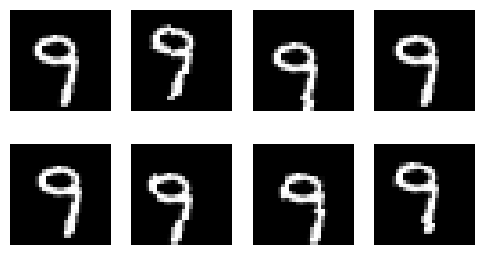

9


In [33]:
# 예제 6-6 같은 사진을 일곱 번 증강
import matplotlib.pyplot as plt
raw = datasets.MNIST(root="data", train=True, download=True) # PIL 사진 그대로
img, label = raw[small_idx[0]] # 학습 데이터 첫 사진
aug = transforms.Compose([transforms.RandomCrop(28, padding=2), # 이동
 transforms.RandomRotation(10)]) # 회전
torch.manual_seed(0)
fig, axes = plt.subplots(2, 4, figsize=(6, 3.2))
axes = axes.ravel() # 8칸을 한 줄로
axes[0].imshow(img, cmap="gray") # 원본
for i in range(1, 8): # 같은 사진을 7번 증강
 axes[i].imshow(aug(img), cmap="gray")
for ax in axes:
 ax.axis("off")
plt.show()
print(label) 

In [35]:
train_tf = transforms.Compose([transforms.RandomCrop(28, padding=2),
                            transforms.RandomRotation(10),
                            transforms.ToTensor()]) # 증강한 뒤 Tensor로
train_aug_all = datasets.MNIST(root="data", train=True, download=True,
                            transform=train_tf) # 같은 MNIST, transform만 다르다
small_aug_loader = DataLoader(Subset(train_aug_all, small_idx), batch_size=64, shuffle=True)
x, y = next(iter(small_aug_loader)) # 꺼낼 때마다 새로 증강된다
print(x.shape, len(small_aug_loader.dataset)) # → torch.Size([64, 1, 28, 28]) 1000

torch.Size([64, 1, 28, 28]) 1000


In [36]:
#1. 예제 6-1을 복사해 로더만 small_aug_loader로 바꿔 학습하기
#예제 6-1. CNN을 1,000장으로 학습하고 두 정확도 비교
torch.manual_seed(0)
model = CNNBN().to(device)
train_losses, val_losses, val_accs = fit(model, small_aug_loader) # 1,000장, 50 epoch
# → (예) best 49 93.88
train_loss, train_acc = evaluate(model, small_aug_loader) # 학습한 1,000장의 정확도
print(round(train_acc, 2), round(val_accs[-1], 2)) # → (예) 100.0 93.73 (학습 데이터 대 검증

best 3 0.16
3.7 0.16


In [38]:
#3. 좌우 뒤집기만 하는 새 로더(RandomHorizontalFlip()과 ToTensor())로 학습해 비교하기

flip_tf = transforms.Compose([transforms.RandomHorizontalFlip(), # 3. 좌우 뒤집기
 transforms.ToTensor()])
flip_all = datasets.MNIST(root="data", train=True, download=True,
 transform=flip_tf) # 새 이름, 예제 6-7은 그대로 둔다
flip_loader = DataLoader(Subset(flip_all, small_idx), batch_size=64, shuffle=True)
torch.manual_seed(0)
model = CNN().to(device)
train_losses, val_losses, val_accs = fit(model, flip_loader)
# → (예) best 32 89.49 (기본 CNN보다 낮다)

best 12 0.15


In [39]:
#예제 6-8. fit에 Early Stopping을 더한 함수
def fit_es(model, loader, patience=10, max_epochs=100): # fit에 Early Stopping을 더했다
    opt = torch.optim.SGD(model.parameters(), lr=0.1)
    best_acc, best_epoch, val_accs = 0.0, 0, []
    for epoch in range(max_epochs):
        train_one_epoch(model, loader, opt)
        vl, va = evaluate(model, val_loader)
        val_accs.append(va)
        if va > best_acc: # 최고 기록이면 저장
            best_acc, best_epoch = va, epoch + 1
            torch.save(model.state_dict(), "best_es.pt")
        elif epoch + 1 - best_epoch >= patience: # patience번 연속 못 넘으면 멈춘다
            break
    print("stop", epoch + 1, "best", best_epoch, round(best_acc, 2))
    model.load_state_dict(torch.load("best_es.pt", map_location=device)) # best로 되돌린다
    return val_accs

In [40]:
#예제 6-9. 1,000장, patience 10, 최대 100 epoch
torch.manual_seed(0)
model = CNN().to(device)
val_accs = fit_es(model, small_loader) # 1,000장, 최대 100 epoch
# → (예) stop 68 best 58 93.91
print(round(evaluate(model, val_loader)[1], 2)) # → (예) 93.91 (best 모델로 되돌아왔다

stop 18 best 8 0.15
0.15


In [41]:
#실습 5. 정답 예시, 1. CNNAll
class CNNAll(nn.Module): # CNNBN과 CNNDrop의 바뀐 곳을 합친다
 def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
    self.bn1 = nn.BatchNorm2d(16)
    self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
    self.bn2 = nn.BatchNorm2d(32)
    self.pool = nn.MaxPool2d(2)
    self.act = nn.ReLU()
    self.flat = nn.Flatten()
    self.drop = nn.Dropout(0.5)
    self.fc = nn.Linear(32 * 7 * 7, 10)
 def forward(self, x):
    x = self.pool(self.act(self.bn1(self.conv1(x))))
    x = self.pool(self.act(self.bn2(self.conv2(x))))
    return self.fc(self.drop(self.flat(x)))

In [42]:
#실습 5. 정답 예시, 2. 증강한 1,000장으로 학습
torch.manual_seed(0)
model = CNNAll().to(device) # 2. BN과 Dropout을 넣은 모델에
train_losses, val_losses, val_accs = fit(model, small_aug_loader) # 증강한 1,000장
# → (예) best 45 97.39
train_loss, train_acc = evaluate(model, small_loader)
print(round(train_acc, 2), round(val_accs[-1], 2)) # → (예) 99.3 96.55

best 9 0.16
3.9 0.16


In [43]:
#3. fit 대신 fit_es
torch.manual_seed(0)
model = CNNAll().to(device)
val_accs = fit_es(model, small_aug_loader) # 3. fit 대신 fit_es, 증강한 1,000장
# → (예) stop 62 best 52 97.43

stop 19 best 9 0.16


In [44]:
#예제 6-10. 지난시간 CNN 학습에서 모델과 로더를 바꿔 10 epoch
train_aug_loader = DataLoader(Subset(train_aug_all, train_set.indices),
            batch_size=64, shuffle=True) # 전체 50,000장, 증강
torch.manual_seed(0) # 지난시간 CNN 학습과 같은 seed, 10 epoch
model = CNNAll().to(device)
opt = torch.optim.SGD(model.parameters(), lr=0.1)
best_acc, best_epoch = 0.0, 0
for epoch in range(10):
    train_one_epoch(model, train_aug_loader, opt)
    vl, va = evaluate(model, val_loader)
    print(epoch + 1, round(va, 2)) # 진행 상황 보기
    if va > best_acc:
        best_acc, best_epoch = va, epoch + 1
        torch.save(model.state_dict(), "exp4_all.pt") # 실험 4
print("best", best_epoch, round(best_acc, 2)) # → (예) best 10 98.7

1 0.16
2 0.15
3 0.16
4 0.16
5 0.15
6 0.15
7 0.16
8 0.16
9 0.15
10 0.16
best 1 0.16


In [46]:
#준비 셀 1. 데이터와 튜닝 실험실
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset, TensorDataset
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic = True # cuDNN도 결정적 계산만
train_all = datasets.MNIST(root="data", train=True, download=True,
                            transform=transforms.ToTensor())
g = torch.Generator().manual_seed(0) # 학습과 검증 분리, seed 0
train_set, val_set = random_split(train_all, [50000, 10000], generator=g)
lab = Subset(train_all, train_set.indices[:10000]) # 새 줄, 튜닝 실험실 1만 장
xs = torch.stack([img for img, _ in lab]) # 사진 1만 장을 한 텐서로
ys = torch.tensor([y for _, y in lab])
xv = torch.stack([img for img, _ in val_set]) # 검증 사진 1만 장도
yv = torch.tensor([y for _, y in val_set])
lab_set = TensorDataset(xs, ys)
val_fast = DataLoader(TensorDataset(xv, yv), batch_size=256, shuffle=False)
print(xs.shape, len(val_fast)) # → torch.Size([10000, 1, 28, 28]) 40

torch.Size([10000, 1, 28, 28]) 40


In [47]:
#준비 셀 2. 지난시간 CNN
class CNN(nn.Module): # 지난시간 CNN 그대로
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.act = nn.ReLU()
        self.flat = nn.Flatten()
        self.fc = nn.Linear(32 * 7 * 7, 10)
    def forward(self, x):
        x = self.pool(self.act(self.conv1(x))) # (N, 16, 14, 14)
        x = self.pool(self.act(self.conv2(x))) # (N, 32, 7, 7)
        return self.fc(self.flat(x))
loss_fn = nn.CrossEntropyLoss()
print(sum(p.numel() for p in CNN().parameters())) # → 20490

20490


In [49]:
#준비 셀 3-1. 검증 함수
def evaluate(model, loader): # 검증 함수, 그대로
 model.eval()
 total_loss, correct = 0.0, 0
 with torch.no_grad():
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += loss_fn(out, y).item() * len(y)
        correct += (out.argmax(dim=1) == y).sum().item()
 n = len(loader.dataset)
 return total_loss / n, correct / n * 100

In [50]:
#준비 셀 3-2. 학습 함수
def train_one_epoch(model, loader, opt): # 학습 함수, 그대로
    model.train()
    total_loss = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total_loss += loss.item() * len(y)
    return total_loss / len(loader.dataset)

In [51]:
#준비 셀 4. 학습과 기록을 함수 하나로
def fit(model, loader, epochs=5, opt=None, sched=None): # sched 자리 추가
    if opt is None: # 따로 주지 않으면 SGD lr 0.1
        opt = torch.optim.SGD(model.parameters(), lr=0.1)
    train_losses, val_losses, val_accs = [], [], []
    for epoch in range(epochs):
        train_losses.append(train_one_epoch(model, loader, opt))
        vl, va = evaluate(model, val_fast) # 검증도 빠른 로더로
        val_losses.append(vl)
        val_accs.append(va)
        if sched is not None: # 새 줄, epoch이 끝나면 lr 조정
            sched.step()
    best = max(val_accs)
    ep = val_accs.index(best) + 1 # best가 몇 번째 epoch인지
    print("best", ep, round(best, 2), "last", round(val_accs[-1], 2))
    return train_losses, val_losses, val_accs

In [52]:
#예제 7-1. 지난시간 1,000장 실험을 빠른 로더로
small_set = TensorDataset(xs[:1000], ys[:1000]) # 지난시간 1,000장과 같은 사진
small_loader = DataLoader(small_set, batch_size=64, shuffle=True)
torch.manual_seed(0)
model = CNN().to(device)
train_losses, val_losses, val_accs = fit(model, small_loader, 50)
# → (예) best 49 93.88 last 93.73 (지난시간 결과와 같다)

best 44 93.89 last 93.72


In [54]:
#예제 7-2. 같은 조건, lr만 바꿔 5 epoch
lab_loader = DataLoader(lab_set, batch_size=64, shuffle=True)
results = {} # lr마다 기록을 모아 둔다
for lr in (0.001, 0.01, 0.1, 1.0):
 torch.manual_seed(0) # 모두 같은 출발점
 model = CNN().to(device)
 opt = torch.optim.SGD(model.parameters(), lr=lr)
 print("lr", lr, end=" ")
 results[lr] = fit(model, lab_loader, 5, opt)
# → (예) lr 0.001 best 5 38.53 last 38.53
# → (예) lr 0.01 best 4 87.72 last 84.67
# → (예) lr 0.1 best 5 96.35 last 96.35
# → (예) lr 1.0 best 1 10.99 last 9.89

lr 0.001 best 5 38.53 last 38.53
lr 0.01 best 4 87.72 last 84.68
lr 0.1 best 5 96.36 last 96.36
lr 1.0 best 1 10.99 last 9.89


In [55]:
#실습 1. 정답 예시
for lr in (0.03, 0.3, 0.5): # 1. 0.01과 1.0 사이를 좁힌다
 torch.manual_seed(0)
 model = CNN().to(device)
 opt = torch.optim.SGD(model.parameters(), lr=lr)
 print("lr", lr, end=" ")
 results[lr] = fit(model, lab_loader, 5, opt)
# → (예) lr 0.03 best 5 93.0 last 93.0
# → (예) lr 0.3 best 3 96.3 last 89.11
# → (예) lr 0.5 best 2 96.47 last 94.84

lr 0.03 best 5 93.0 last 93.0
lr 0.3 best 3 96.41 last 92.57
lr 0.5 best 3 96.16 last 95.24
